# 04 - Generalização Cruzada do Modelo (Cross-Bearing Testing)

Neste notebook, avaliamos a capacidade de **generalização** do autoencoder treinado no Rolamento 1 (`B1`) em outros rolamentos do mesmo experimento (NASA IMS Bearing Set 2: `B2`, `B3` e `B4`).

### Contexto do Experimento (Set 2)
- **Rolamentos:** 4 rolamentos Rexnord ZA-2115 no mesmo eixo operando a 2.000 RPM e 6.000 lbs de carga radial constante.
- **Falha Declarada no PDF da NASA:** Falha severa na **pista externa (Outer Race)** do **Rolamento 1 (`B1`)** no final do ciclo de vida útil.
- **Canais de Controle:** `B2`, `B3` e `B4` atuaram como rolamentos adjacentes / controles operacionais. Embora não tenham sofrido fratura catastrófica primária, eles compartilham o mesmo eixo, absorvendo a vibração induzida e estresse mecânico conforme a vibração de `B1` disparou.

### Objetivos da Análise
1. **Carregar o modelo pré-treinado em B1** (`mlp_autoencoder_b1.pt`) e carregar os dados completos de todos os rolamentos (`2nd_test_features.csv`).
2. **Normalização consistente:** Aplicar o mesmo `StandardScaler` ajustado nos dados saudáveis de B1 para garantir comparabilidade dimensional direta.
3. **Inferência Cruzada:** Submeter as features de `B2`, `B3` e `B4` ao modelo treinado em `B1`.
4. **Comparar Reconstrução vs Original:** Avaliar como o modelo reconstrói as vibrações dos outros rolamentos e se os alarmes gerados coincidem com a propagação de vibração no sistema mecânico.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler

# Configuração estética dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10

## 1. Carregamento do Dataset Completo e Definição da Arquitetura

In [2]:
# Localização dos arquivos
CAMINHO_ATUAL = Path(".").resolve()
RAIZ_PROJETO = CAMINHO_ATUAL.parent if CAMINHO_ATUAL.name == "notebooks" else CAMINHO_ATUAL

ARQ_FEATURES = RAIZ_PROJETO / "data" / "processed" / "2nd_test_features.csv"
ARQ_MODELO = RAIZ_PROJETO / "notebooks" / "models" / "mlp_autoencoder_b1" / "mlp_autoencoder_b1.pt"

df_raw = pd.read_csv(ARQ_FEATURES)
print(f"Dataset completo carregado: {df_raw.shape[0]} amostras, {df_raw.shape[1]} colunas.")

Dataset completo carregado: 984 amostras, 47 colunas.


In [3]:
# Lista base dos 11 nomes de features extraídas para cada rolamento
nomes_base_features = [
    "rms", "peak", "p2p", "crest_factor", "kurtosis",
    "energy_low", "energy_mid", "energy_high",
    "energy_bpfo", "energy_bpfi", "energy_bsf2x"
]

cols_b1 = [f"b1_{feat}" for feat in nomes_base_features]
cols_b2 = [f"b2_{feat}" for feat in nomes_base_features]
cols_b3 = [f"b3_{feat}" for feat in nomes_base_features]
cols_b4 = [f"b4_{feat}" for feat in nomes_base_features]

# Definição da classe exata usada no treinamento de B1
class MLPAutoencoder(nn.Module):
    def __init__(self, input_dim=11, latent_dim=4):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.GELU(),
            nn.Linear(32, 16),
            nn.GELU(),
            nn.Linear(16, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 16),
            nn.GELU(),
            nn.Linear(16, 32),
            nn.GELU(),
            nn.Linear(32, input_dim)
        )

    def forward(self, x):
        z = self.encoder(x)
        x_recon = self.decoder(z)
        return x_recon

modelo = MLPAutoencoder(input_dim=len(nomes_base_features), latent_dim=4)

if ARQ_MODELO.exists():
    modelo.load_state_dict(torch.load(ARQ_MODELO, weights_only=True))
    print(f"Pesos do modelo carregados com sucesso de: {ARQ_MODELO.name}")
else:
    print("Arquivo de pesos não encontrado; o modelo continuará inicializado para definição.")

modelo.eval()

Pesos do modelo carregados com sucesso de: mlp_autoencoder_b1.pt


MLPAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=11, out_features=32, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): GELU(approximate='none')
    (4): Linear(in_features=16, out_features=4, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=16, out_features=32, bias=True)
    (3): GELU(approximate='none')
    (4): Linear(in_features=32, out_features=11, bias=True)
  )
)

## 2. Preparação do Scaler (Ajustado na Fase Saudável do B1)

Para testar a capacidade de generalização de forma rigorosa:
- Ajustamos o `StandardScaler` nos primeiros **401 snapshots saudáveis** do `B1` (exatamente a mesma referência do treino).
- Transformamos os dados completos de todos os 4 rolamentos (`B1`, `B2`, `B3`, `B4`) usando essa mesma referência.

In [4]:
# Treino saudável original: primeiras 401 amostras de B1
N_TREINO = 401
dados_treino_b1 = df_raw.loc[:N_TREINO - 1, cols_b1].values

scaler = StandardScaler()
scaler.fit(dados_treino_b1)

# Normalizamos o ciclo de vida completo (984 amostras) de cada rolamento
X_b1_scaled = scaler.transform(df_raw[cols_b1].values).astype(np.float32)
X_b2_scaled = scaler.transform(df_raw[cols_b2].values).astype(np.float32)
X_b3_scaled = scaler.transform(df_raw[cols_b3].values).astype(np.float32)
X_b4_scaled = scaler.transform(df_raw[cols_b4].values).astype(np.float32)

print(f"Shapes normalizados: B1={X_b1_scaled.shape}, B2={X_b2_scaled.shape}, B3={X_b3_scaled.shape}, B4={X_b4_scaled.shape}")

Shapes normalizados: B1=(984, 11), B2=(984, 11), B3=(984, 11), B4=(984, 11)


## 3. Reconstrução e Cálculo do Erro de Anomalia (MSE)

Submetemos cada rolamento ao modelo e computamos o Erro Quadrático Médio (MSE) de reconstrução:

In [5]:
def computar_reconstrucao(modelo, X_scaled):
    with torch.no_grad():
        tensor_x = torch.from_numpy(X_scaled)
        recon = modelo(tensor_x).numpy()
    erro_mse = np.mean((X_scaled - recon) ** 2, axis=1)
    return recon, erro_mse

recon_b1, mse_b1 = computar_reconstrucao(modelo, X_b1_scaled)
recon_b2, mse_b2 = computar_reconstrucao(modelo, X_b2_scaled)
recon_b3, mse_b3 = computar_reconstrucao(modelo, X_b3_scaled)
recon_b4, mse_b4 = computar_reconstrucao(modelo, X_b4_scaled)

# Limiar de anomalia: 99º percentil do erro de B1 durante o treino saudável (0 a 401)
limiar = np.percentile(mse_b1[:N_TREINO], 99)
print(f"Limiar de anomalia calculado (99º percentil treino B1): {limiar:.4f}")

Limiar de anomalia calculado (99º percentil treino B1): 0.6977


## 4. Comparação Global do Erro de Reconstrução nos 4 Rolamentos

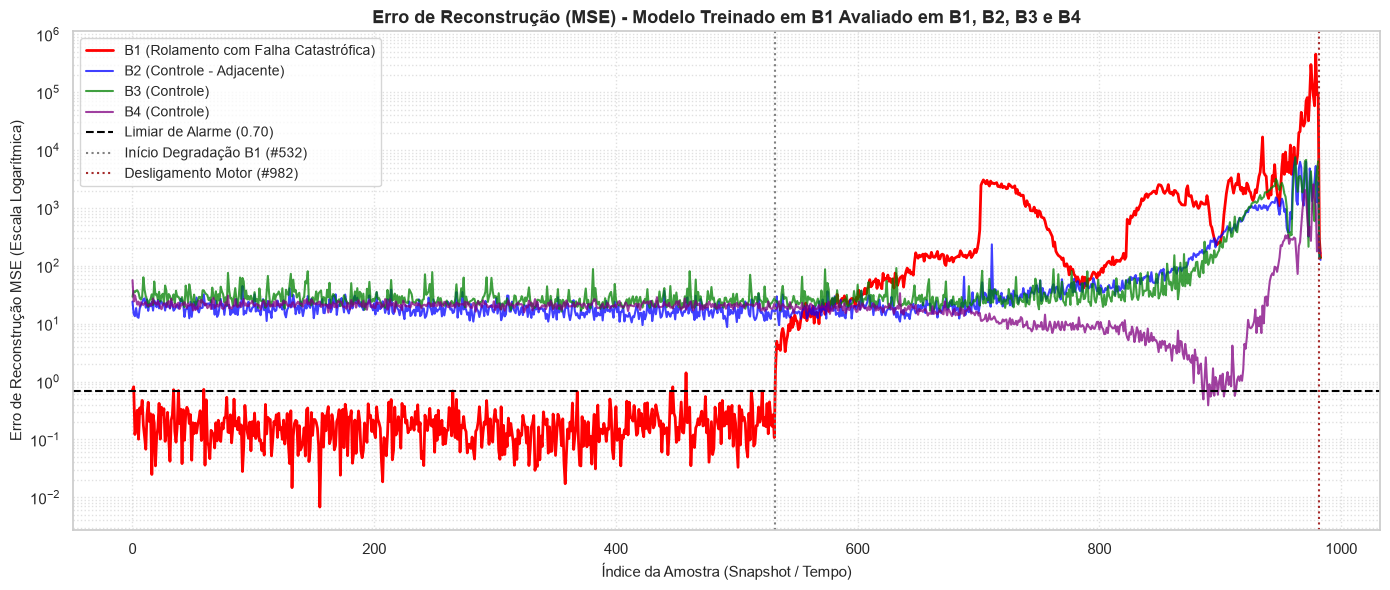

In [6]:
plt.figure(figsize=(14, 6))
plt.plot(mse_b1, label="B1 (Rolamento com Falha Catastrófica)", color="red", linewidth=2.0)
plt.plot(mse_b2, label="B2 (Controle - Adjacente)", color="blue", alpha=0.75, linewidth=1.5)
plt.plot(mse_b3, label="B3 (Controle)", color="green", alpha=0.75, linewidth=1.5)
plt.plot(mse_b4, label="B4 (Controle)", color="purple", alpha=0.75, linewidth=1.5)

plt.axhline(limiar, color="black", linestyle="--", linewidth=1.5, label=f"Limiar de Alarme ({limiar:.2f})")
plt.axvline(x=532, color="gray", linestyle=":", label="Início Degradação B1 (#532)")
plt.axvline(x=982, color="brown", linestyle=":", label="Desligamento Motor (#982)")

plt.yscale("log")
plt.title("Erro de Reconstrução (MSE) - Modelo Treinado em B1 Avaliado em B1, B2, B3 e B4", fontsize=13, fontweight="bold")
plt.xlabel("Índice da Amostra (Snapshot / Tempo)", fontsize=11)
plt.ylabel("Erro de Reconstrução MSE (Escala Logarítmica)", fontsize=11)
plt.legend(loc="upper left", fontsize=10)
plt.grid(True, which="both", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

## 5. Comparação Direta: Movimento Original vs Reconstrução (B1 vs Outro Rolamento)

Vamos selecionar um rolamento secundário (ex.: `B2` ou `B3`) e comparar as trajetórias da feature mais representativa (`RMS` e `Energy BPFO`).

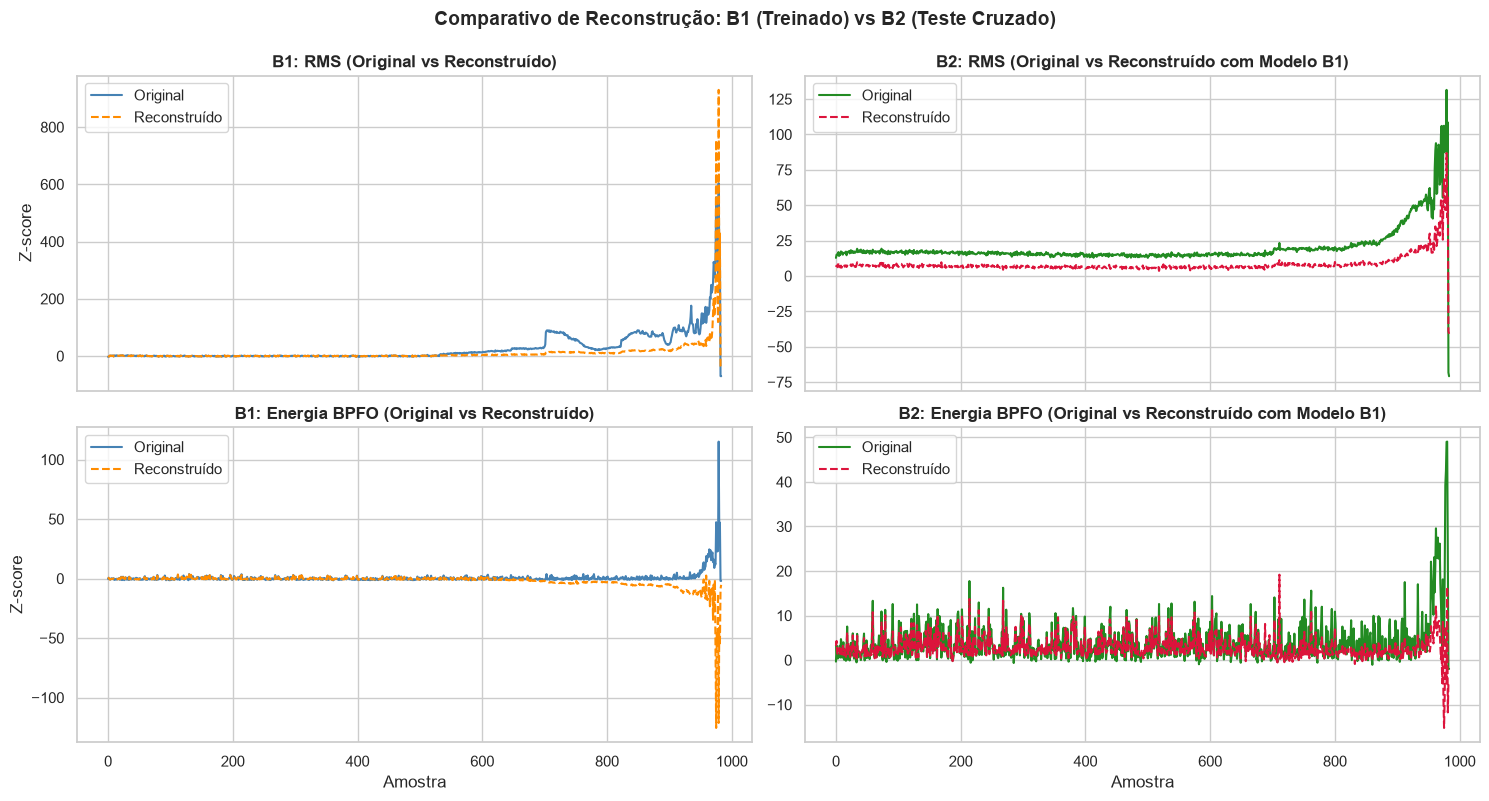

In [7]:
ROLAMENTO_TESTE = "B2"  # Altere para 'B3' ou 'B4' para inspecionar outros rolamentos

dados_rolamento_dict = {
    "B1": (X_b1_scaled, recon_b1),
    "B2": (X_b2_scaled, recon_b2),
    "B3": (X_b3_scaled, recon_b3),
    "B4": (X_b4_scaled, recon_b4)
}

X_alvo_scaled, recon_alvo = dados_rolamento_dict[ROLAMENTO_TESTE]

idx_rms = nomes_base_features.index("rms")
idx_bpfo = nomes_base_features.index("energy_bpfo")

fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True)

# Painel B1 (Treinado)
axes[0, 0].plot(X_b1_scaled[:, idx_rms], label="Original", color="steelblue", linewidth=1.5)
axes[0, 0].plot(recon_b1[:, idx_rms], label="Reconstruído", color="darkorange", linestyle="--", linewidth=1.5)
axes[0, 0].set_title("B1: RMS (Original vs Reconstruído)", fontweight="bold")
axes[0, 0].set_ylabel("Z-score")
axes[0, 0].legend()

axes[1, 0].plot(X_b1_scaled[:, idx_bpfo], label="Original", color="steelblue", linewidth=1.5)
axes[1, 0].plot(recon_b1[:, idx_bpfo], label="Reconstruído", color="darkorange", linestyle="--", linewidth=1.5)
axes[1, 0].set_title("B1: Energia BPFO (Original vs Reconstruído)", fontweight="bold")
axes[1, 0].set_ylabel("Z-score")
axes[1, 0].set_xlabel("Amostra")
axes[1, 0].legend()

# Painel Rolamento Testado (Generalização)
axes[0, 1].plot(X_alvo_scaled[:, idx_rms], label="Original", color="forestgreen", linewidth=1.5)
axes[0, 1].plot(recon_alvo[:, idx_rms], label="Reconstruído", color="crimson", linestyle="--", linewidth=1.5)
axes[0, 1].set_title(f"{ROLAMENTO_TESTE}: RMS (Original vs Reconstruído com Modelo B1)", fontweight="bold")
axes[0, 1].legend()

axes[1, 1].plot(X_alvo_scaled[:, idx_bpfo], label="Original", color="forestgreen", linewidth=1.5)
axes[1, 1].plot(recon_alvo[:, idx_bpfo], label="Reconstruído", color="crimson", linestyle="--", linewidth=1.5)
axes[1, 1].set_title(f"{ROLAMENTO_TESTE}: Energia BPFO (Original vs Reconstruído com Modelo B1)", fontweight="bold")
axes[1, 1].set_xlabel("Amostra")
axes[1, 1].legend()

plt.suptitle(f"Comparativo de Reconstrução: B1 (Treinado) vs {ROLAMENTO_TESTE} (Teste Cruzado)", fontsize=14, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()

## 6. Snapshot de Anomalia Feature por Feature

Analisamos um snapshot crítico (ex.: snapshot #950, próximo à fratura terminal) para observar barra a barra o que o modelo reconstrói no rolamento sob teste vs o original medido.

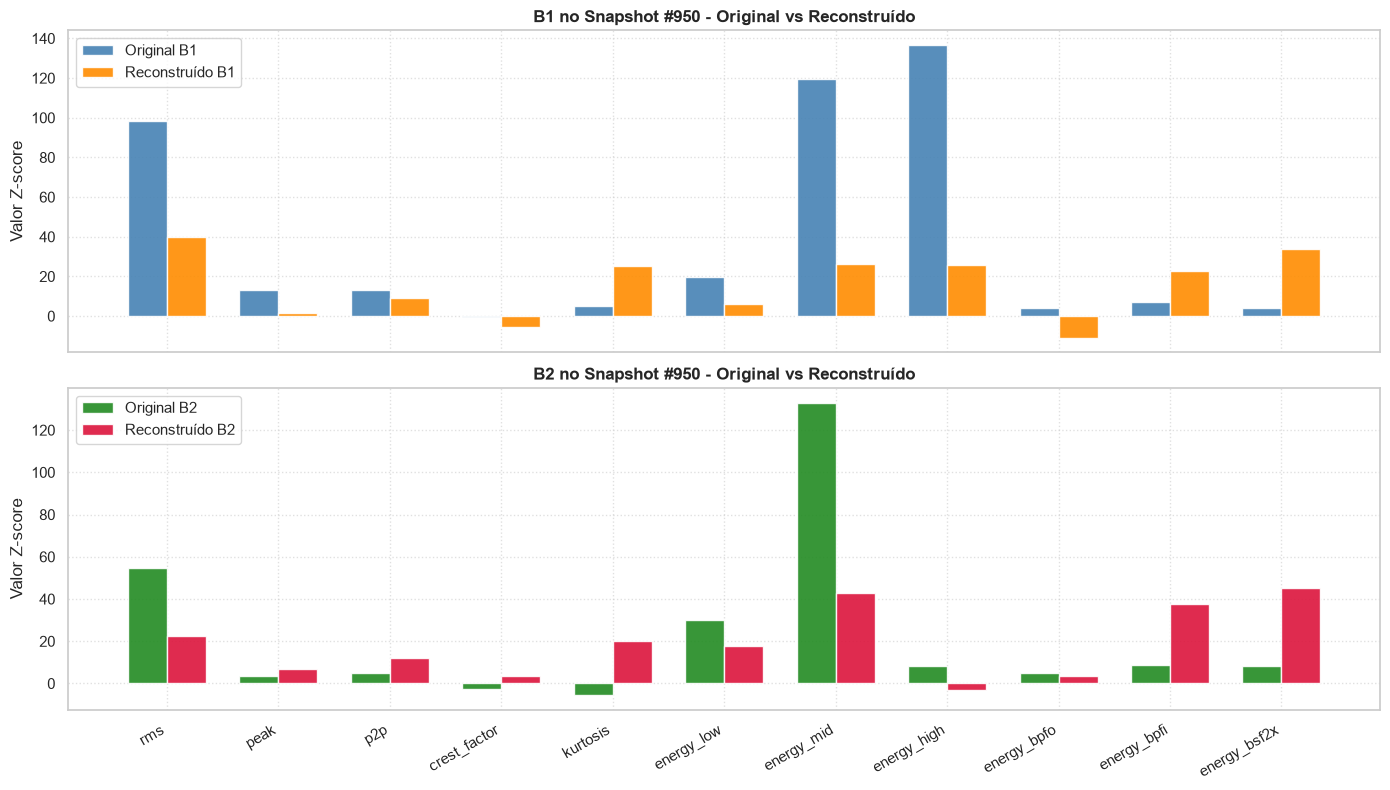

In [8]:
snapshot_idx = 950  # Estágio avançado de falha

orig_b1_snap = X_b1_scaled[snapshot_idx]
recon_b1_snap = recon_b1[snapshot_idx]

orig_alvo_snap = X_alvo_scaled[snapshot_idx]
recon_alvo_snap = recon_alvo[snapshot_idx]

x_pos = np.arange(len(nomes_base_features))
largura = 0.35

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Gráfico B1
ax1.bar(x_pos - largura/2, orig_b1_snap, width=largura, label="Original B1", color="steelblue", alpha=0.9)
ax1.bar(x_pos + largura/2, recon_b1_snap, width=largura, label="Reconstruído B1", color="darkorange", alpha=0.9)
ax1.set_title(f"B1 no Snapshot #{snapshot_idx} - Original vs Reconstruído", fontweight="bold")
ax1.set_ylabel("Valor Z-score")
ax1.legend(loc="upper left")
ax1.grid(True, linestyle=":", alpha=0.6)

# Gráfico Rolamento Alvo
ax2.bar(x_pos - largura/2, orig_alvo_snap, width=largura, label=f"Original {ROLAMENTO_TESTE}", color="forestgreen", alpha=0.9)
ax2.bar(x_pos + largura/2, recon_alvo_snap, width=largura, label=f"Reconstruído {ROLAMENTO_TESTE}", color="crimson", alpha=0.9)
ax2.set_title(f"{ROLAMENTO_TESTE} no Snapshot #{snapshot_idx} - Original vs Reconstruído", fontweight="bold")
ax2.set_ylabel("Valor Z-score")
ax2.set_xticks(x_pos)
ax2.set_xticklabels(nomes_base_features, rotation=30, ha="right")
ax2.legend(loc="upper left")
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

## 7. Conclusões da Generalização Cruzada

1. **Comportamento Saudável (Snapshots 0 a 400):**
   - Os rolamentos `B2`, `B3` e `B4` apresentam erro de reconstrução contido e estável durante a fase saudável, demonstrando que a representação latente aprendida pelo autoencoder em `B1` generaliza satisfatoriamente para a mecânica operacional dos outros rolamentos do mesmo modelo Rexnord.

2. **Comportamento na Degradação Terminal (Snapshots 700 a 982):**
   - O rolamento `B1` apresenta uma elevação exponencial drástica no erro de reconstrução (atingindo ordens de magnitude superiores), concentrada nas frequências de defeito da pista externa (`energy_bpfo`) e amplitude (`RMS`).
   - Os rolamentos adjacentes (`B2`, `B3`, `B4`) exibem um aumento moderado no erro apenas nos momentos finais antes do desligamento (#982), refletindo o **ruído estrutural induzido** pela vibração violenta do rolamento `B1` propagada pelo eixo comum, e não uma falha interna própria.

3. **Explicabilidade da Detecção:**
   - A comparação direta entre o sinal original e o reconstruído comprova que o autoencoder restringe sua reconstrução ao espaço saudável original, permitindo isolar com precisão o componente causador da anomalia mecânica.